In [1]:
import json
import matplotlib.pyplot as plt

In [11]:
with open("load_test_results.json", "r") as f:
    testcases = json.load(f)

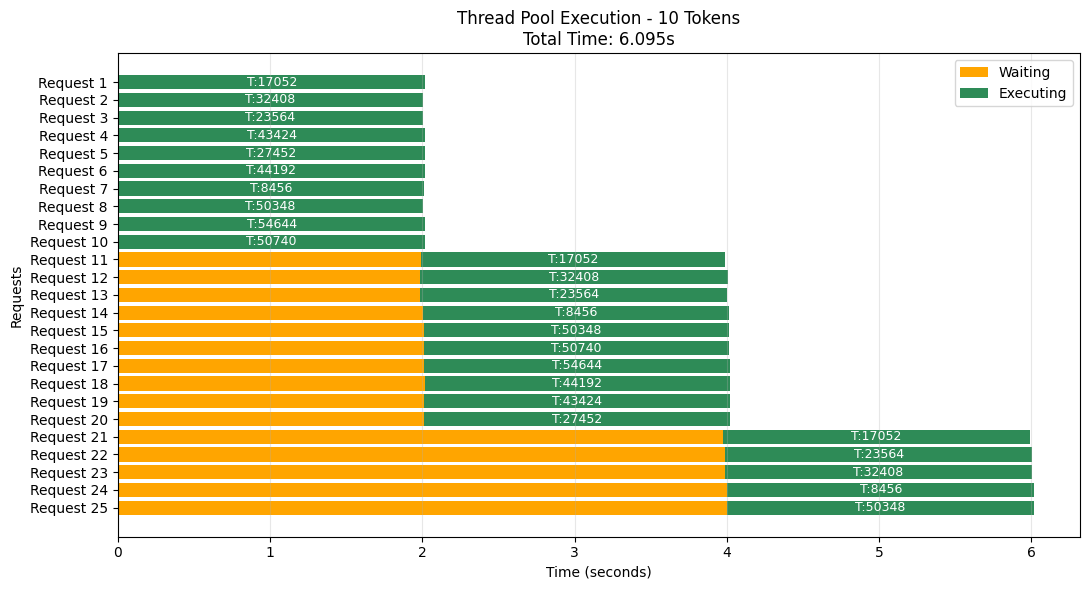

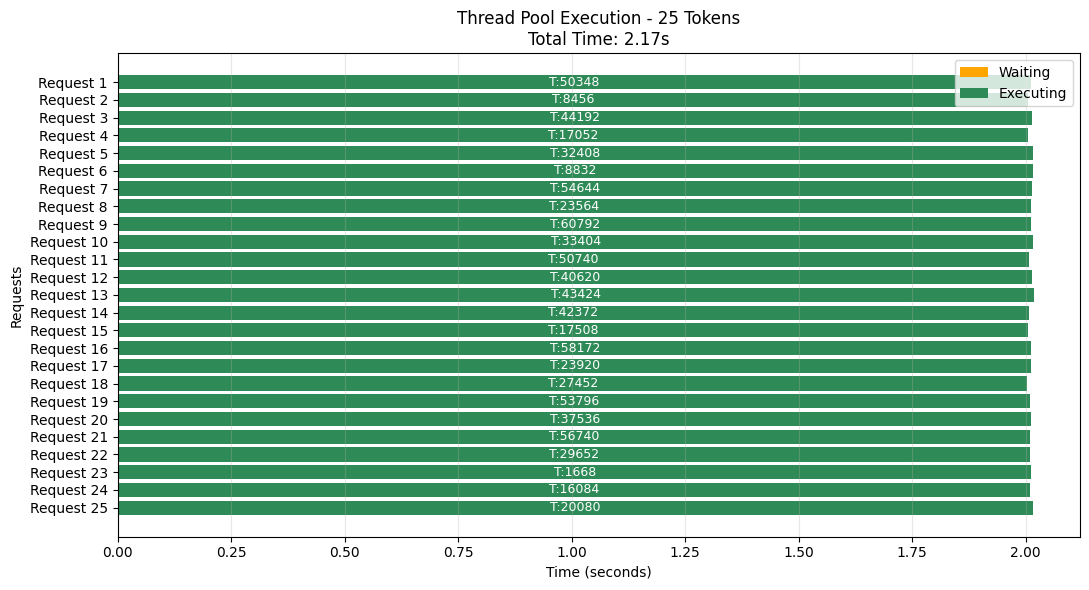

In [12]:
for testcase in testcases:
    stats = testcase["thread execution stats"]
    max_tokens = testcase["max_tokens"]

    fig, ax = plt.subplots(figsize=(11, 6))

    for index, req in enumerate(stats):
        request_id = req["request_id"]
        wait = req["waiting_time"]
        execution = req["execution_time"]

        # Waiting period
        ax.barh(
            index, wait,
            left=0,
            color="orange",
            label="Waiting" if index == 0 else ""
        )

        # Execution period
        ax.barh(
            index, execution,
            left=wait,
            color="seagreen",
            label="Executing" if index == 0 else ""
        )

        # Display thread ID
        ax.text(
            wait + execution / 2,
            index,
            f"T:{req['thread_id']}",
            ha="center",
            va="center",
            fontsize=9,
            color="white"
        )

    ax.set_yticks(range(len(stats)))
    ax.set_yticklabels(
        [f"Request {r['request_id']}" for r in stats]
    )

    ax.invert_yaxis()
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Requests")
    ax.set_title(
        f"Thread Pool Execution - {max_tokens} Tokens\n"
        f"Total Time: {testcase['total_execution_time']}s"
    )

    ax.legend()
    ax.grid(axis="x", alpha=0.3)

    plt.tight_layout()
    plt.show()